In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()

# If VS Code starts Jupyter from inside the notebooks folder
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "backend" / "data" / "WELFake.csv"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Dataset path: c:\Projects\fake_news_detection_extension\backend\data\WELFake.csv
Dataset exists: True


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Check your project structure."
    )

df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")

display(df.head())

Rows: 72,134
Columns: 3


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,NaN,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [3]:
print('Column names:')
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Column names:
['title', 'text', 'label']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   71576 non-null  str  
 1   text    72095 non-null  str  
 2   label   72134 non-null  int64
dtypes: int64(1), str(2)
memory usage: 234.4 MB


In [4]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary.sort_values(
    "Missing_Percentage", ascending=False
))

,Missing_Count,Missing_Percentage
title,558,0.77
text,39,0.05
label,0,0.00


In [5]:
print("Exact duplicate rows:", df.duplicated().sum())

text_columns = [
    column for column in ["title", "text"]
    if column in df.columns
]

if text_columns:
    print(
        "Duplicate title/text combinations:",
        df.duplicated(subset=text_columns).sum()
    )

Exact duplicate rows: 8456
Duplicate title/text combinations: 8456


In [6]:
if "label" not in df.columns:
    raise ValueError("The expected 'label' column is missing.")

print("Label counts:")
display(df["label"].value_counts(dropna=False).to_frame("Count"))

print("Label percentages:")
display(
    (df["label"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("Percentage")
)

Label counts:


,Count
label,
1,37106
0,35028


Label percentages:


,Percentage
label,
1,51.44
0,48.56


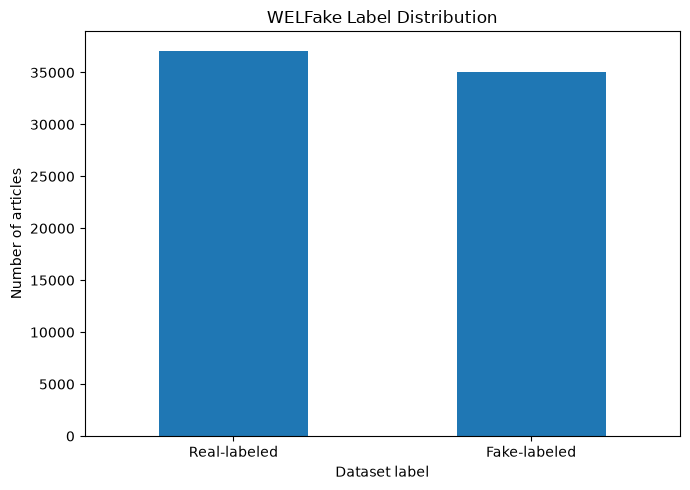

In [7]:
label_names = {0: "Fake-labeled", 1: "Real-labeled"}

plot_labels = (
    df["label"]
    .map(label_names)
    .fillna(df["label"].astype(str))
)

ax = plot_labels.value_counts().plot(
    kind="bar",
    figsize=(7, 5),
    rot=0
)

ax.set_title("WELFake Label Distribution")
ax.set_xlabel("Dataset label")
ax.set_ylabel("Number of articles")

plt.tight_layout()
plt.show()

,Word_Count
count,72134.000000
mean,540.550933
std,625.399748
min,0.000000
25%,227.000000
50%,398.000000
75%,667.000000
max,24234.000000


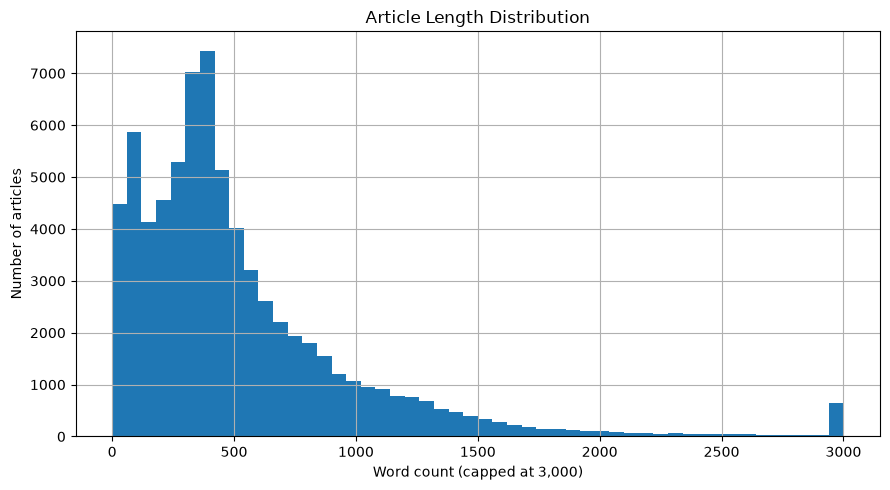

In [8]:
if "text" in df.columns:
    article_lengths = (
        df["text"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    display(article_lengths.describe().to_frame("Word_Count"))

    article_lengths.clip(upper=3000).hist(bins=50, figsize=(9, 5))
    plt.title("Article Length Distribution")
    plt.xlabel("Word count (capped at 3,000)")
    plt.ylabel("Number of articles")
    plt.tight_layout()
    plt.show()